In [22]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path
from arch.bootstrap import MCS

df = pd.read_csv("../data/GSPC_processed.csv", index_col=0, parse_dates=True)
r = df["log_return"]
n = len(r)
split = int(n * 0.8)                      # same split as notebooks 03-08
test_idx = r.index[split:]
train = r.index < r.index[split]
print("Test:", test_idx[0].date(), "->", test_idx[-1].date(), f"({len(test_idx)} days)")

Test: 2023-06-06 -> 2026-10-16 (845 days)


In [23]:
lnHL = np.log(df["High"] / df["Low"])
lnCO = np.log(df["Close"] / df["Open"])
lnON = np.log(df["Open"] / df["Close"].shift(1))     # overnight: previous close -> today's open

parkinson = 1e4 * lnHL ** 2 / (4 * np.log(2))       # x 1e4 puts everything in %^2, like r**2
gk = 1e4 * (0.5 * lnHL ** 2 - (2 * np.log(2) - 1) * lnCO ** 2)
gk_on = (gk + 1e4 * lnON ** 2).loc[r.index]
sq_ret = r ** 2

print("Data checks")
print(f"  days with High == Low:            {(df['High'] == df['Low']).mean():.2%}")
print(f"  days with Open == previous Close: {np.isclose(df['Open'], df['Close'].shift(1)).mean():.2%}")
print(f"  missing values in GK + overnight: {gk_on.isna().sum()}")

# Fixed scale (kept for comparison): one number from the training period
scale = sq_ret[train].mean() / gk_on[train].mean()

# Time-varying scale: ratio over the trailing 252 days, using only data up to the previous day.
# The first ~6 months have no history, so they borrow the first available value (training period only).
roll_scale = (sq_ret.rolling(252, min_periods=126).sum()
              / gk_on.rolling(252, min_periods=126).sum()).shift(1).bfill()
proxy_rb = (roll_scale * gk_on).clip(lower=1e-6)

print(f"\nFixed scale (training): {scale:.3f}")
print(f"Rolling scale: min {roll_scale.min():.3f}, max {roll_scale.max():.3f}, "
      f"test-period mean {roll_scale[~train].mean():.3f}")
print(f"Check, mean r^2 / mean proxy in test period: {sq_ret[~train].mean() / proxy_rb[~train].mean():.3f}  (should be close to 1)")

Data checks
  days with High == Low:            0.00%
  days with Open == previous Close: 4.64%
  missing values in GK + overnight: 1

Fixed scale (training): 1.507
Rolling scale: min 0.965, max 2.002, test-period mean 1.150
Check, mean r^2 / mean proxy in test period: 0.988  (should be close to 1)


,std / mean,lag-1 autocorrelation
Squared returns,3.921,0.429
GK + overnight (scaled),3.124,0.664


Correlation between the two proxies: 0.752
Higher autocorrelation = more of the true (persistent) volatility signal, less noise.


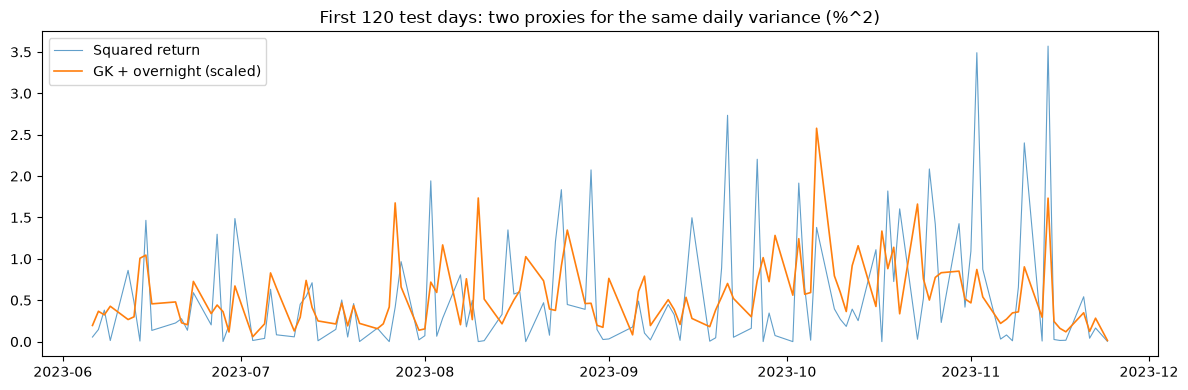

In [24]:
# How much less noisy is it? Compare each proxy's day-to-day dispersion relative to its own level.
def rel_noise(x):
    x = x.dropna()
    return x.std() / x.mean()

comp = pd.DataFrame({
    "std / mean": [rel_noise(sq_ret), rel_noise(proxy_rb)],
    "lag-1 autocorrelation": [sq_ret.autocorr(1), proxy_rb.autocorr(1)],
}, index=["Squared returns", "GK + overnight (scaled)"])
display(comp.round(3))
print("Correlation between the two proxies:", round(sq_ret.corr(proxy_rb), 3))
print("Higher autocorrelation = more of the true (persistent) volatility signal, less noise.")

fig, ax = plt.subplots(figsize=(12, 4))
window = r.index[split:split + 120]
ax.plot(window, sq_ret.loc[window], lw=0.8, alpha=0.7, label="Squared return")
ax.plot(window, proxy_rb.loc[window], lw=1.2, label="GK + overnight (scaled)")
ax.set_title("First 120 test days: two proxies for the same daily variance (%^2)")
ax.legend(); plt.tight_layout(); plt.show()

In [25]:
REFIT_EVERY = 20

def har_design(x):
    """Row t holds information up to and including day t; it forecasts day t+1."""
    return pd.DataFrame({"daily": x, "weekly": x.rolling(5).mean(), "monthly": x.rolling(22).mean()})

def rolling_har(series, log=False):
    x = np.log(series) if log else series
    X = sm.add_constant(har_design(x))
    y_next = x.shift(-1)                     # target: next day's value
    preds, params = [], None
    for s in range(split, n, REFIT_EVERY):
        e = min(s + REFIT_EVERY, n)
        # Train on origins t whose target t+1 is before day s, i.e. rows 0 .. s-2
        Xt, yt = X.iloc[: s - 1], y_next.iloc[: s - 1]
        ok = Xt.notna().all(axis=1) & yt.notna()
        res = sm.OLS(yt[ok], Xt[ok]).fit()
        # Forecasts for test days s .. e-1 come from origins s-1 .. e-2
        p = res.predict(X.iloc[s - 1: e - 1])
        if log:
            p = np.exp(p + 0.5 * res.mse_resid)
        preds.append(pd.Series(p.values, index=r.index[s:e]))
        params = res
    return pd.concat(preds), params

floor = 0.01 * proxy_rb[train].mean()
har, har_fit = rolling_har(proxy_rb)
n_clipped = (har < floor).sum()
har = har.clip(lower=floor)
loghar, loghar_fit = rolling_har(proxy_rb, log=True)

print(f"HAR (levels): {n_clipped} forecasts clipped at the floor")
print("\nLast HAR fit (levels):")
print(har_fit.params.round(4))
print("\nLast log-HAR fit:")
print(loghar_fit.params.round(4))
print("\nPersistence (sum of daily + weekly + monthly):",
      round(har_fit.params[1:].sum(), 3), "(levels),", round(loghar_fit.params[1:].sum(), 3), "(log)")

HAR (levels): 0 forecasts clipped at the floor

Last HAR fit (levels):
const      0.2183
daily      0.4298
weekly     0.3395
monthly    0.0464
dtype: float64

Last log-HAR fit:
const     -0.0721
daily      0.2460
weekly     0.4508
monthly    0.1949
dtype: float64

Persistence (sum of daily + weekly + monthly): 0.816 (levels), 0.892 (log)


In [26]:
# HAR fitted on squared returns: same model, same target as the other models
har_sq, _ = rolling_har(sq_ret.clip(lower=1e-4))
har_sq = har_sq.clip(lower=floor)

# Is the scale factor stable over time? Where are the stale opens?
stale = pd.Series(np.isclose(df["Open"], df["Close"].shift(1)), index=df.index)
display(pd.DataFrame({
    "r2 / GK ratio": sq_ret.groupby(sq_ret.index.year).mean() / gk_on.groupby(gk_on.index.year).mean(),
    "stale opens %": 100 * stale.groupby(stale.index.year).mean(),
}).round(2))
print("Ratio in training:", round(scale, 3), "| in test:", round(sq_ret[~train].mean() / gk_on[~train].mean(), 3))

,r2 / GK ratio,stale opens %
Date,,
2010,1.38,2.79
2011,1.98,10.32
2012,1.50,29.20
2013,1.71,29.76
2014,1.62,0.79
2015,1.89,1.59
2016,1.46,0.40
2017,1.08,1.20
2018,1.22,0.00


Ratio in training: 1.507 | in test: 1.124


In [27]:
fc = pd.read_csv("../data/garch_forecasts.csv", index_col=0, parse_dates=True)
fc = fc.rename(columns=lambda c: c if c.startswith("Rolling 21d") else f"{c} (fixed)")

files = [("../data/rolling_garch_forecasts.csv", None),
         ("../data/lstm_qlike_forecasts.csv", "LSTM (QLIKE)"),
         ("../data/hybrid_qlike_forecasts.csv", "Hybrid (QLIKE)")]
for path, label in files:
    if Path(path).exists():
        x = pd.read_csv(path, index_col=0, parse_dates=True)
        if label:
            x = x.iloc[:, [0]]
            x.columns = [label]
        fc = fc.join(x, how="inner")
    else:
        print("Not found, skipping:", path)

fc = (fc.join(har.rename("HAR"), how="inner")
        .join(loghar.rename("log-HAR"), how="inner")
        .join(har_sq.rename("HAR (r² inputs)"), how="inner"))
fc = fc.dropna().clip(lower=1e-8)
print(fc.shape)
print(list(fc.columns))

(845, 12)
['GARCH(1,1) (fixed)', 'EGARCH (fixed)', 'GJR-GARCH (fixed)', 'Rolling 21d var', 'GARCH(1,1) (rolling)', 'EGARCH (rolling)', 'GJR-GARCH (rolling)', 'LSTM (QLIKE)', 'Hybrid (QLIKE)', 'HAR', 'log-HAR', 'HAR (r² inputs)']


In [28]:
proxies = {"Squared returns": sq_ret.loc[fc.index], "GK + overnight": proxy_rb.loc[fc.index]}

def daily_qlike(p):
    return fc.apply(lambda f: np.log(f) + p / f)

losses = {name: daily_qlike(p) for name, p in proxies.items()}
tab = pd.DataFrame({name: L.mean() for name, L in losses.items()})
for name in proxies:
    tab[f"rank ({name})"] = tab[name].rank().astype(int)
display(tab.sort_values("GK + overnight").round(4))

from scipy.stats import spearmanr
print("Spearman correlation of the two rankings:",
      round(spearmanr(tab["Squared returns"], tab["GK + overnight"])[0], 3))

,Squared returns,GK + overnight,rank (Squared returns),rank (GK + overnight)
Hybrid (QLIKE),0.5546,0.5463,1,1
GJR-GARCH (rolling),0.5788,0.5583,5,2
GJR-GARCH (fixed),0.5829,0.5610,6,3
EGARCH (rolling),0.5856,0.5671,7,4
EGARCH (fixed),0.5882,0.5683,8,5
log-HAR,0.5654,0.5708,2,6
HAR,0.5676,0.5746,3,7
LSTM (QLIKE),0.5687,0.5793,4,8
"GARCH(1,1) (rolling)",0.6370,0.6036,9,9
"GARCH(1,1) (fixed)",0.6408,0.6055,11,10


Spearman correlation of the two rankings: 0.699


In [29]:
def dm_test(L_a, L_b, lags=5):
    d = (L_a - L_b).values
    res = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return res.tvalues[0], res.pvalues[0]

BASE = "GJR-GARCH (fixed)"
rows = {}
for m in fc.columns:
    if m == BASE:
        continue
    row = {}
    for name, L in losses.items():
        s_, p_ = dm_test(L[m], L[BASE])
        row[f"DM ({name})"], row[f"p ({name})"] = s_, p_
    rows[m] = row
dm_tab = pd.DataFrame(rows).T
print(f"Diebold-Mariano vs {BASE}: negative = model has lower loss")
display(dm_tab.round(3))

ratio = (dm_tab["DM (GK + overnight)"].abs() / dm_tab["DM (Squared returns)"].abs()).median()
print(f"Median |DM| ratio (range proxy / squared returns): {ratio:.2f}  (> 1 means the better proxy gives sharper tests)")

Diebold-Mariano vs GJR-GARCH (fixed): negative = model has lower loss


,DM (Squared returns),p (Squared returns),DM (GK + overnight),p (GK + overnight)
"GARCH(1,1) (fixed)",3.405,0.001,3.814,0.000
EGARCH (fixed),0.443,0.658,1.130,0.258
Rolling 21d var,3.337,0.001,4.389,0.000
"GARCH(1,1) (rolling)",3.127,0.002,3.574,0.000
EGARCH (rolling),0.219,0.827,0.892,0.373
GJR-GARCH (rolling),-2.418,0.016,-2.726,0.006
LSTM (QLIKE),-0.418,0.676,0.711,0.477
Hybrid (QLIKE),-2.058,0.040,-1.655,0.098
HAR,-0.642,0.521,0.964,0.335
log-HAR,-0.901,0.368,0.648,0.517


Median |DM| ratio (range proxy / squared returns): 1.32  (> 1 means the better proxy gives sharper tests)


In [30]:
for name, L in losses.items():
    mcs = MCS(L, size=0.10, reps=2000, seed=42)
    mcs.compute()
    print(f"{name}: 90% MCS contains {len(mcs.included)} of {L.shape[1]} models")
    print("  ", list(mcs.included), "\n")

Squared returns: 90% MCS contains 7 of 12 models
   ['EGARCH (fixed)', 'EGARCH (rolling)', 'GJR-GARCH (rolling)', 'HAR', 'Hybrid (QLIKE)', 'LSTM (QLIKE)', 'log-HAR'] 

GK + overnight: 90% MCS contains 7 of 12 models
   ['EGARCH (fixed)', 'EGARCH (rolling)', 'GJR-GARCH (rolling)', 'HAR', 'Hybrid (QLIKE)', 'LSTM (QLIKE)', 'log-HAR'] 



In [31]:
rows = {}
for m in fc.columns:
    row = {}
    for name, p in proxies.items():
        res = sm.OLS(p.values, sm.add_constant(fc[m].values)).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        row[f"slope ({name})"] = res.params[1]
        row[f"slope SE ({name})"] = res.bse[1]
        row[f"joint p ({name})"] = float(res.wald_test("const = 0, x1 = 1", scalar=True).pvalue)
    rows[m] = row
mz = pd.DataFrame(rows).T
display(mz.round(3))
print("Median slope SE, squared returns:", round(mz["slope SE (Squared returns)"].median(), 3),
      "| GK + overnight:", round(mz["slope SE (GK + overnight)"].median(), 3))

# Fair precision comparison: SE relative to the slope, so the proxy's 1.5x scale doesn't distort it
for name in proxies:
    rel = (mz[f"slope SE ({name})"] / mz[f"slope ({name})"].abs()).median()
    print(f"Median SE / slope, {name}: {rel:.3f}")

,slope (Squared returns),slope SE (Squared returns),joint p (Squared returns),slope (GK + overnight),slope SE (GK + overnight),joint p (GK + overnight)
"GARCH(1,1) (fixed)",0.616,0.260,0.286,0.742,0.327,0.576
EGARCH (fixed),1.336,0.475,0.142,1.462,0.480,0.076
GJR-GARCH (fixed),0.984,0.323,0.242,1.112,0.334,0.042
Rolling 21d var,0.423,0.256,0.000,0.494,0.249,0.000
"GARCH(1,1) (rolling)",0.638,0.273,0.349,0.764,0.339,0.679
EGARCH (rolling),1.400,0.503,0.156,1.524,0.504,0.098
GJR-GARCH (rolling),1.029,0.343,0.290,1.158,0.355,0.070
LSTM (QLIKE),1.955,0.958,0.457,1.924,0.821,0.504
Hybrid (QLIKE),1.255,0.437,0.572,1.379,0.419,0.323
HAR,1.118,0.319,0.186,0.888,0.160,0.617


Median slope SE, squared returns: 0.333 | GK + overnight: 0.347
Median SE / slope, Squared returns: 0.357
Median SE / slope, GK + overnight: 0.329


In [32]:
# Save for later notebooks (e.g. re-running notebook 10 with the new proxy, or adding range features to the hybrid)
pd.DataFrame({"HAR": har, "log-HAR": loghar}).to_csv("../data/har_forecasts.csv")
pd.DataFrame({"gk_overnight_scaled": proxy_rb, "parkinson": parkinson.loc[r.index]}).to_csv("../data/range_proxy.csv")
print("Saved har_forecasts.csv and range_proxy.csv")

Saved har_forecasts.csv and range_proxy.csv
